## U-Net Baseline
After preprocessing and looking into my data, I will now do the baseline for this project. For this, based on my **Research Models** document, which can be found in the folder **docs**, I chose to start with a standard U-Net and work my way up in more complex models to figure out which one can perform the best and also compare them.

## Importing and Loading Data

In [1]:
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from pathlib import Path
from PIL import Image

SEED=42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)
print("Seed:", SEED)

PyTorch version: 2.15.0+cpu
Device: cpu
Seed: 42


c:\Users\Francisco\Desktop\Work\Semester 3\Main Challenge\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Reusing the Preprocessing

Import the preprocessing and dataset defined in notebook 02 from `src/dataset.py`. This loads the definitions without rerunning the notebook or recreating the splits.


In [2]:
import sys

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from src.dataset import LandCoverDataset

## Loading Splits

In [3]:
pairs_df = pd.read_csv("../results/tables/split_manifest.csv")

split_summary = pairs_df.groupby("split").agg(
        Images=("image", "count"),
        Regions=("region", "nunique")
)

display(split_summary.reindex(["train", "validation", "test"]))

,Images,Regions
split,,
train,1942,52
validation,275,11
test,470,12


## Loading Training and Validation Batches
Reuse the saved region assignments and the same 512 x 512 preprocessing.


In [4]:
loaders = {}

for split in ["train", "validation"]:
    data = LandCoverDataset(pairs_df[pairs_df["split"] == split])
    loaders[split] = DataLoader(
        data,
        batch_size=2,
        shuffle=(split == "train"),
        num_workers=0,
        generator=torch.Generator().manual_seed(SEED)
    )

images, masks = next(iter(loaders["train"]))

loaders["train"].generator.manual_seed(SEED)

assert images.shape == (2, 3, 512, 512)
assert masks.shape == (2, 512, 512)
assert images.dtype == torch.float32
assert masks.dtype == torch.int64
assert images.min() >= 0 and images.max() <= 1
assert (((masks >= 0) & (masks <= 7)) | (masks == 255)).all()

print("Images:", images.shape)
print("Masks:", masks.shape)
print("Batch checks passed.")


Images: torch.Size([2, 3, 512, 512])
Masks: torch.Size([2, 512, 512])
Batch checks passed.


The saved splits contain 1,942 training pairs, 275 validation pairs and
470 test pairs, across 52, 11 and 12 regions respectively.

The inspected batch contains two RGB images with shape `(2, 3, 512, 512)`
and two masks with shape `(2, 512, 512)`. All checks passed, confirming
the expected shapes, data types, image value range and valid mask IDs.

## Convolution Block
The U-Net uses repeated blocks of two 3 x 3 convolutions, each followed by a ReLU activation to learn image features.
The first convolution maps the input channels to the chosen number of output channels. The second keeps the number.

In [5]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.layer = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU()
        )

    def forward(self, x):
        return self.layer(x)

In [6]:
class Down(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layer = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(in_channels, out_channels)
        )

    def forward(self, x):
        return self.layer(x)

In [7]:
class Up(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        
        self.conv = DoubleConv(out_channels * 2, out_channels)
        
    def forward(self, x1, skip):
        x1 = self.up(x1)
        x = torch.cat([x1, skip], dim=1)
        return self.conv(x)

In [12]:
class UNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=8):
        super().__init__()

        # Encoder
        self.initial = DoubleConv(in_channels, 16)
        self.down1 = Down(16, 32)
        self.down2 = Down(32, 64)
        self.down3 = Down(64, 128)
        self.down4 = Down(128, 256)

        # Decoder
        self.up1 = Up(256, 128)
        self.up2 = Up(128, 64)
        self.up3 = Up(64, 32)
        self.up4 = Up(32, 16)

        # One score per class, for each pixel
        self.output = nn.Conv2d(16, num_classes, kernel_size=1)

    def forward(self, x):
        x1 = self.initial(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)

        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)

        return self.output(x)

In [13]:
torch.manual_seed(SEED)

model = UNet().to(device)
model.eval()

sample = images[:1].to(device)

with torch.no_grad():
    logits = model(sample)

assert logits.shape == (1, 8, 512, 512)
assert torch.isfinite(logits).all()

print("Input:", sample.shape)
print("Output:", logits.shape)
print("Network checks passed.")

Input: torch.Size([1, 3, 512, 512])
Output: torch.Size([1, 8, 512, 512])
Network checks passed.


Two 3 × 3 convolutions extract features while preserving image size. In this lightweight U-Net, `DoubleConv(3, 16)` transforms the 3 RGB channels into 16 feature maps.

The number of filters is reduced to decrease computational complexity, memory consumption and training time while maintaining the original architecture depth, skip connections and spatial dimensions.

The final layer still produces 8 class scores per pixel.

## Checking Architecture Validation

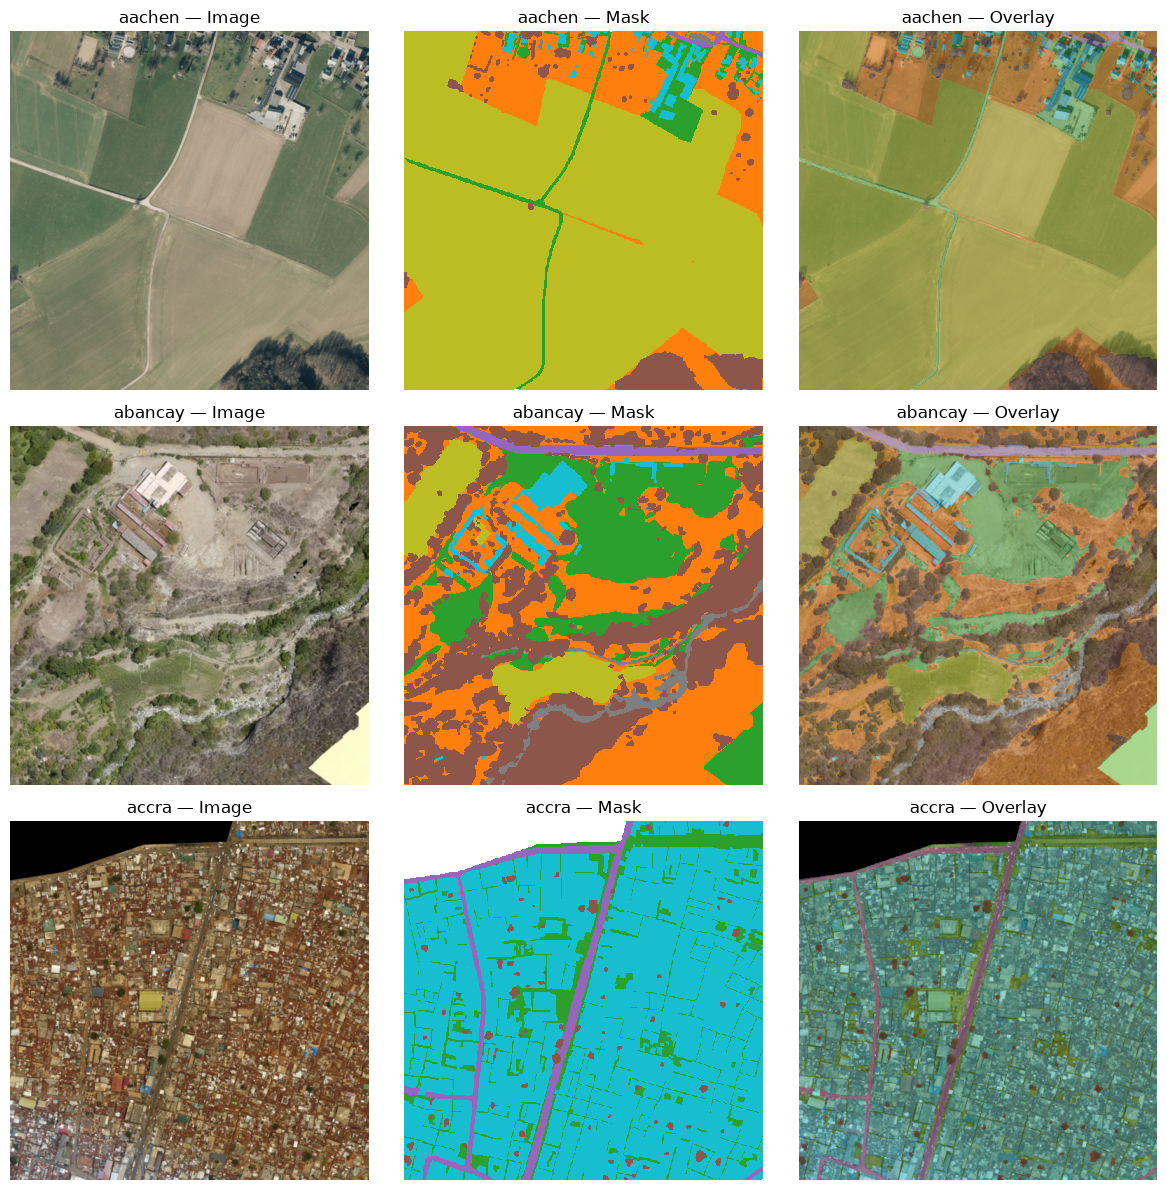

In [14]:
examples=(
    pairs_df[pairs_df["split"] == "train"].drop_duplicates("region").head(3)
)

example_data=LandCoverDataset(examples)

fig, axes = plt.subplots(3, 3, figsize=(12,12))
for i in range(3):
    image, mask = example_data[i]

    image=image.permute(1, 2, 0).numpy()
    mask=np.ma.masked_where(mask == 255, mask)

    axes[i, 0].imshow(image)

    axes[i, 1].imshow(
        mask, cmap="tab10", vmin=0, vmax=7,
        interpolation="nearest"
    )

    axes[i, 2].imshow(image)
    axes[i, 2].imshow(
        mask, cmap="tab10", vmin=0, vmax=7,
        interpolation="nearest", alpha=0.4
    )

    region = examples.iloc[i]["region"]

    for ax, title in zip(axes[i], ["Image", "Mask", "Overlay"]):
        ax.set_title(f"{region} — {title}")
        ax.axis("off")

plt.tight_layout()
plt.show()

It is quite clear that the masks overlay almost perfectly to the three inspected images of the training split. Based on this images, the preprocessing phase is done and it is working well (as far as these images showcase this), so now I can start with the modelling part.
Baseline model will be done based on the belief that the preprocessing part is correct.

## Loss of the Model
For the loss, I will use **Cross-Entropy** to start and after finishing this baseline, I will add **Dice Loss** to check whether it improves the model or not.
Cross-Entropy compares the predicted class scores to the correct label per pixel. Unkown pixels(255) will be ignored in this part and no softmax will be applied before the loss.

In [15]:
criterion = nn.CrossEntropyLoss(ignore_index=255)

loss = criterion(logits, masks[:1].to(device))

assert torch.isfinite(loss)
print("Initial loss:", loss.item())

Initial loss: 2.1499929428100586


The inital Cross-Entropy Loss is approximately 2.099 on one training image, excluding Uknown pixels.

## Evaluation Metrics
Based on my research and also using information from [the OpenEarthMap paper (Xia et al., 2023)](https://openaccess.thecvf.com/content/WACV2023/papers/Xia_OpenEarthMap_A_Benchmark_Dataset_for_Global_High-Resolution_Land_Cover_Mapping_WACV_2023_paper.pdf), the evaluation metrics will use global mIoU, Dice and per-class IoU. The Uknown pixels once again are not taken into account.

In [16]:
def compute_confusion_matrix(predictions, targets):
    predictions = predictions.detach().cpu()
    targets=targets.detach().cpu()

    valid= targets != 255
    indices=8*targets[valid]+predictions[valid]

    return torch.bincount(indices, minlength=64).reshape(8, 8)

In [17]:
def compute_metrics(confusion_matrix):
    counts = confusion_matrix.float()

    correct=counts.diagonal() 
    actual=counts.sum(dim=1)
    predicted=counts.sum(dim=0)

    iou = correct / (actual + predicted - correct)
    dice=2*correct/(actual+predicted)

    return pd.DataFrame({
        "IoU": iou.numpy(),
        "Dice": dice.numpy(),
    }).rename_axis("Class ID")

The confusion matrix counts true and predicted classes. Its diagonal are the correct prediction, each line is the correct class and each column the prediction. Of course, there is no evaluation for now, but for the IoU and Dice calculations, it will simply use the confusion matrix values for its results.
Classes absent from both targets and predictions will not count into these averages.

## Optimizer and Backpropagation
This is an essential step, as with this the model can update its weights using gradients calculated by backpropagation (Adam).

In [18]:
optimizer=torch.optim.Adam(model.parameters(), lr=0.001)

model.train()
optimizer.zero_grad(set_to_none=True)

logits=model(images[:1].to(device))
targets=masks[:1].to(device)

loss=criterion(logits, targets)
loss.backward()

print("Loss:", loss.item())
print("Backward checks passed.")

optimizer.zero_grad(set_to_none=True)

Loss: 2.133490800857544
Backward checks passed.


Checks done on one training image

## Training the Model

In [ ]:
EPOCHS = 1

torch.manual_seed(SEED)
loaders["train"].generator.manual_seed(SEED)
model = UNet().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    total_pixels = 0
    confusion = torch.zeros(8, 8, dtype=torch.int64)

    for images, masks in tqdm(loaders["train"]):
        images = images.to(device)
        masks = masks.to(device)

        pixels = (masks != 255).sum().item()
        if pixels == 0:
            continue

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, masks)
        assert torch.isfinite(loss)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * pixels
        total_pixels += pixels
        confusion += compute_confusion_matrix(logits.argmax(1), masks)

    assert total_pixels > 0
    scores = compute_metrics(confusion)

    print(f"Epoch {epoch + 1}")
    print(f"Loss: {total_loss / total_pixels:.4f}")
    print(f"mIoU: {scores['IoU'].mean():.4f}")
    print(f"Dice: {scores['Dice'].mean():.4f}")
    display(scores)

Epoch 1
Loss: 1.5561
mIoU: 0.1666
Dice: 0.2652


,IoU,Dice
Class ID,,
0,0.000030,0.000059
1,0.191191,0.321008
2,0.212647,0.350716
3,0.039990,0.076905
4,0.347926,0.516239
5,0.039494,0.075986
6,0.148667,0.258851
7,0.352675,0.521449


## Saving "Model"

In [ ]:
save_path = Path("../results/models/unet_baseline.pth")
save_path.parent.mkdir(parents=True, exist_ok=True)

torch.save({
    "epoch": EPOCHS,
    "model": model.state_dict(),
    "optimizer": optimizer.state_dict(),
    "train_loss": total_loss / total_pixels,
    "train_miou": scores["IoU"].mean(),
    "train_dice": scores["Dice"].mean()
}, save_path)

print(f"Model saved: {save_path}")

Model saved: ..\results\models\unet_baseline.pth


## Kaggle Lending

In [ ]:
from pathlib import Path
from zipfile import ZipFile
import pandas as pd

manifest = Path("../results/tables/split_manifest.csv")
pairs = pd.read_csv(manifest)
zip_path = Path("../data/kaggle_baseline.zip")

with ZipFile(zip_path, "x") as archive:
    archive.write(manifest, "split_manifest.csv")
    archive.write("../src/dataset.py", "dataset.py")

    for i, row in enumerate(pairs.itertuples(), start=1):
        for file in [row.image, row.mask]:
            path = Path(file)
            archive.write(path, path.relative_to("../data"))

        if i % 250 == 0:
            print(f"{i}/{len(pairs)} pairs added")

print(f"ZIP ready: {zip_path}")

250/2687 pairs added
500/2687 pairs added
750/2687 pairs added
1000/2687 pairs added
1250/2687 pairs added
1500/2687 pairs added
1750/2687 pairs added
2000/2687 pairs added
2250/2687 pairs added
2500/2687 pairs added
ZIP ready: ..\data\kaggle_baseline.zip
